In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

In [25]:
%matplotlib inline
#Visual Styling
sns.set_theme(style = "whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

In [26]:
#Load Dataset
df = pd.read_csv('retail_sales_dataset.csv')

#Convert Date Column
df["Date"] = pd.to_datetime(df["Date"])
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [27]:
# Display dataset shape (rows, columns)
display(df.shape)

(1000, 9)

In [28]:
#Data type & missing values
inspection_summary = pd.DataFrame({
    "Data Type" : df.dtypes,
    "Missing Values" : df.isnull().sum()
})
display(inspection_summary)

,Data Type,Missing Values
Transaction ID,int64,0
Date,datetime64[us],0
Customer ID,str,0
Gender,str,0
Age,int64,0
Product Category,str,0
Quantity,int64,0
Price per Unit,int64,0
Total Amount,int64,0


In [29]:
#Select numerical columns(excluding transaction ID)
num_cols = ["Age", "Quantity", "Price per Unit", "Total Amount"]

#Calculate metrics
stats_df = pd.DataFrame({
    "Mean" : df[num_cols].mean(),
    "Median" : df[num_cols].median(),
    "Mode" : df[num_cols].mode().iloc[0],
    "Std Dev" : df[num_cols].std()
}).round(2)

#Display summary dataframe
stats_df

,Mean,Median,Mode,Std Dev
Age,41.39,42.0,43.0,13.68
Quantity,2.51,3.0,4.0,1.13
Price per Unit,179.89,50.0,50.0,189.68
Total Amount,456.00,135.0,50.0,560.00


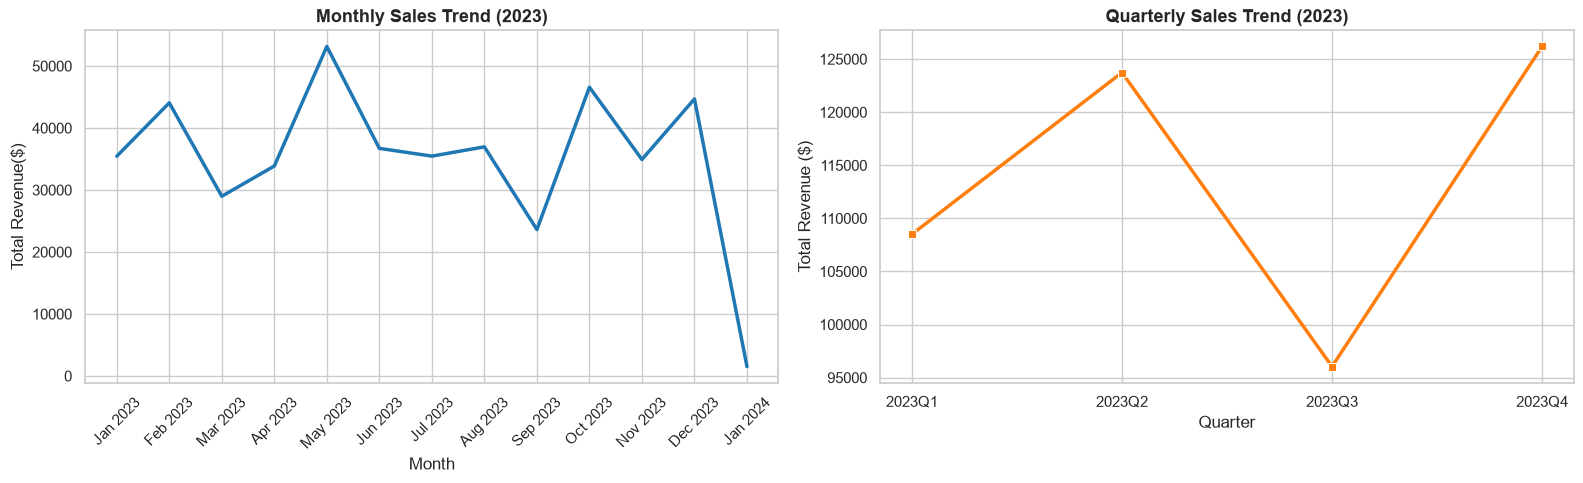

,Month,Monthly Revenue ($)
0,Jan 2023,35450
1,Feb 2023,44060
2,Mar 2023,28990
3,Apr 2023,33870
4,May 2023,53150
5,Jun 2023,36715
6,Jul 2023,35465
7,Aug 2023,36960
8,Sep 2023,23620
9,Oct 2023,46580


,Quarter,Quarterly Revenue ($)
0,2023Q1,108500
1,2023Q2,123735
2,2023Q3,96045
3,2023Q4,126190


In [30]:
#Resample sales data
monthly_df = df.set_index("Date").resample("MS")["Total Amount"].sum().reset_index()
quarterly_df = df.set_index("Date").resample("QS")["Total Amount"].sum().reset_index()

#Filter out incomplete single-day quarter entry (e.g., 2024-01-01) for clean visual plotting
quarterly_df = quarterly_df[quarterly_df["Date"].dt.year == 2023]

# Create period labels
monthly_df["Month"] = monthly_df["Date"].dt.strftime("%b %Y")
quarterly_df["Quarter"] = quarterly_df["Date"].dt.to_period("Q").astype(str)

#Plot trends
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

#Monthly line chart
sns.lineplot(data=monthly_df, x="Month", y="Total Amount", markers="o", color="#1f77b4", linewidth=2.5, ax=axes[0])
axes[0].set_title("Monthly Sales Trend (2023)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Total Revenue($)")
axes[0].tick_params(axis="x", rotation = 45)

# Quarterly Line Chart
sns.lineplot(data=quarterly_df, x="Quarter", y="Total Amount", marker="s", color="#ff7f0e", linewidth=2.5, ax=axes[1])
axes[1].set_title("Quarterly Sales Trend (2023)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Quarter")
axes[1].set_ylabel("Total Revenue ($)")

plt.tight_layout()
plt.show()

#Display Clean Summaries in notebook
display(monthly_df[["Month", "Total Amount"]].rename(columns={"Total Amount": "Monthly Revenue ($)"}))
display(quarterly_df[["Quarter", "Total Amount"]].rename(columns={"Total Amount": "Quarterly Revenue ($)"}))

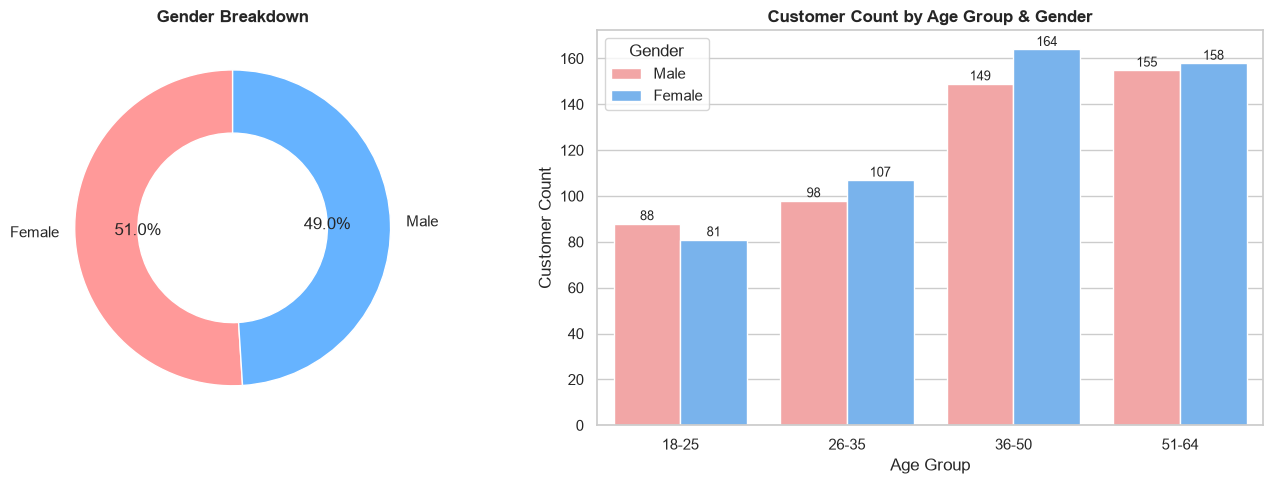

,Gender,Count,Percentage
0,Female,510,51.0
1,Male,490,49.0


,Age Group,Count,Percentage
0,18-25,169,16.9
1,26-35,205,20.5
2,36-50,313,31.3
3,51-64,313,31.3


Gender,Age Group,Female,Male
0,18-25,81,88
1,26-35,107,98
2,36-50,164,149
3,51-64,158,155


In [31]:
#Bin Age into Demographics Groups
bins = [17, 25, 35, 50, 65]
labels = ["18-25", "26-35", "36-50", "51-64"]
df["Age Group"] = pd.cut(df["Age"], bins=bins, labels=labels)

# Create Demographics DataFrames
gender_summary = df["Gender"].value_counts().reset_index()
gender_summary.columns = ["Gender", "Count"]
gender_summary["Percentage"] = (gender_summary["Count"] / len(df) * 100).round(2)

age_summary = df["Age Group"].value_counts().sort_index().reset_index()
age_summary.columns = ["Age Group", "Count"]
age_summary["Percentage"] = (age_summary["Count"] / len(df) * 100).round(2)

age_gender_ct = pd.crosstab(df["Age Group"], df["Gender"]).reset_index()

# Plot Visualizations
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Gender Distribution (Donut Chart)
colors = ["#ff9999", "#66b3ff"]
axes[0].pie(
    gender_summary["Count"],
    labels=gender_summary["Gender"],
    autopct="%1.1f%%",
    startangle=90,
    colors=colors,
    wedgeprops=dict(width=0.4, edgecolor="w")
)
axes[0].set_title("Gender Breakdown", fontsize=12, fontweight="bold")

# Plot 2: Age Group Distribution by Gender (Stacked/Grouped Bar Chart)
sns.countplot(
    data=df,
    x="Age Group",
    hue="Gender",
    palette=["#ff9999", "#66b3ff"],
    ax=axes[1]
)
axes[1].set_title("Customer Count by Age Group & Gender", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Age Group")
axes[1].set_ylabel("Customer Count")

# Annotate bars with counts
for p in axes[1].patches:
    height = p.get_height()
    if height > 0:
        axes[1].annotate(
            f"{int(height)}",
            (p.get_x() + p.get_width() / 2.0, height),
            ha="center",
            va="center",
            xytext=(0, 5),
            textcoords="offset points",
            fontsize=9
        )

plt.tight_layout()
plt.show()

# Display Summaries in Notebook
display(gender_summary)
display(age_summary)
display(age_gender_ct)

C:\Users\Sandhya\AppData\Local\Temp\ipykernel_6820\206213018.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\Sandhya\AppData\Local\Temp\ipykernel_6820\206213018.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


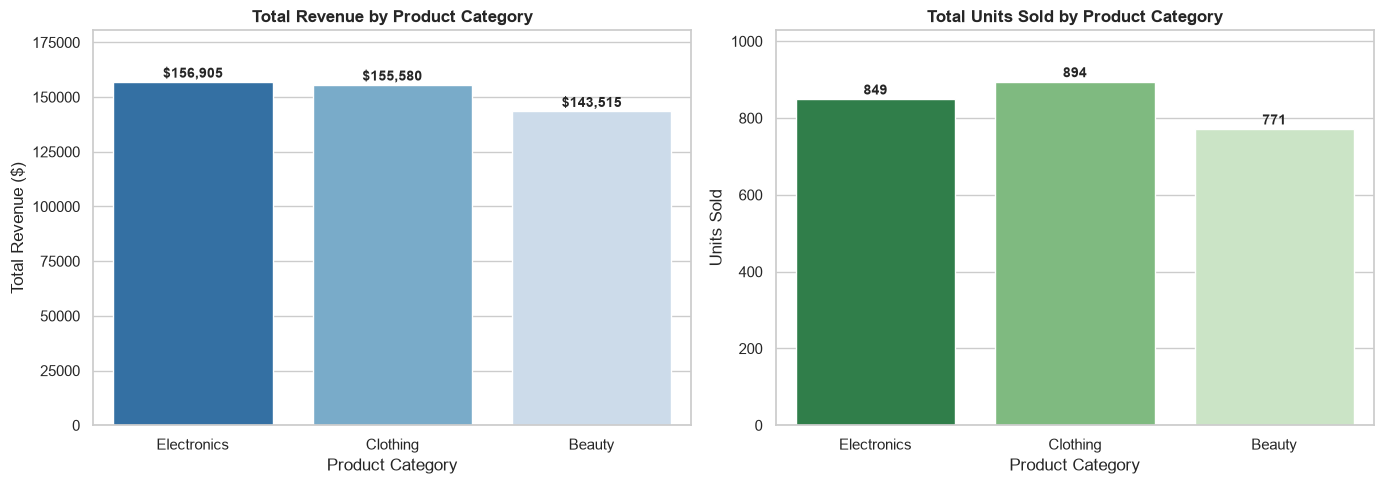

,Product Category,Total_Quantity,Total_Revenue,Total_Transactions,Avg_Transaction_Value
0,Electronics,849,"$156,905.00",342,$458.79
1,Clothing,894,"$155,580.00",351,$443.25
2,Beauty,771,"$143,515.00",307,$467.48


In [32]:
#Aggregations by Product Category
category_summary = (
    df.groupby("Product Category")
    .agg(
        Total_Quantity=("Quantity", "sum"),
        Total_Revenue=("Total Amount", "sum"),
        Total_Transactions=("Transaction ID", "count"),
        Avg_Transaction_Value=("Total Amount", "mean")
    )
    .sort_values(by="Total_Revenue", ascending=False)
    .reset_index()
)

# Side-by-Side Plots: Revenue and Quantity by Product Category
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Chart 1: Revenue by Category
sns.barplot(
    data=category_summary,
    x="Product Category",
    y="Total_Revenue",
    palette="Blues_r",
    ax=axes[0]
)
axes[0].set_title("Total Revenue by Product Category", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Product Category")
axes[0].set_ylabel("Total Revenue ($)")

for p in axes[0].patches:
    axes[0].annotate(
        f"${p.get_height():,.0f}",
        (p.get_x() + p.get_width() / 2.0, p.get_height()),
        ha="center",
        va="center",
        xytext=(0, 6),
        textcoords="offset points",
        fontsize=10,
        fontweight="bold"
    )
axes[0].set_ylim(0, category_summary["Total_Revenue"].max() * 1.15)

# Chart 2: Quantity Sold by Category
sns.barplot(
    data=category_summary,
    x="Product Category",
    y="Total_Quantity",
    palette="Greens_r",
    ax=axes[1]
)
axes[1].set_title("Total Units Sold by Product Category", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Product Category")
axes[1].set_ylabel("Units Sold")

for p in axes[1].patches:
    axes[1].annotate(
        f"{p.get_height():,.0f}",
        (p.get_x() + p.get_width() / 2.0, p.get_height()),
        ha="center",
        va="center",
        xytext=(0, 6),
        textcoords="offset points",
        fontsize=10,
        fontweight="bold"
    )
axes[1].set_ylim(0, category_summary["Total_Quantity"].max() * 1.15)

plt.tight_layout()
plt.show()

# Display Formatted Summary Table
display(category_summary.style.format({
    "Total_Quantity": "{:,}",
    "Total_Revenue": "${:,.2f}",
    "Total_Transactions": "{:,}",
    "Avg_Transaction_Value": "${:,.2f}"
}))

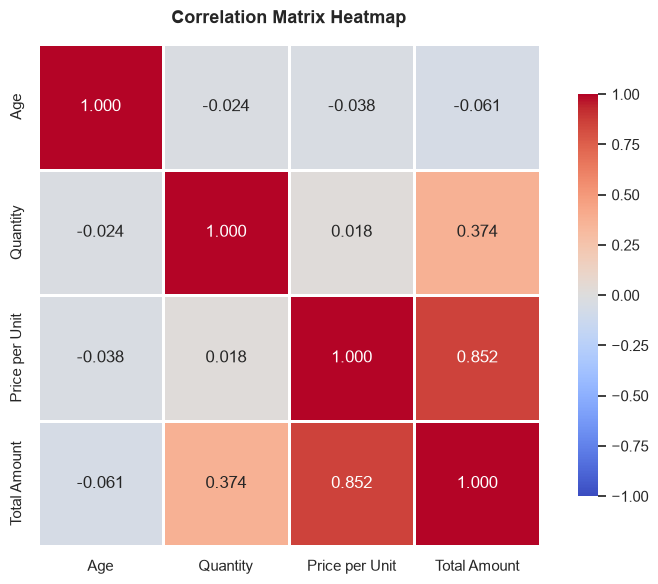

,Age,Quantity,Price per Unit,Total Amount
Age,1.000,-0.024,-0.038,-0.061
Quantity,-0.024,1.000,0.018,0.374
Price per Unit,-0.038,0.018,1.000,0.852
Total Amount,-0.061,0.374,0.852,1.000


In [33]:
# Select numerical columns (excluding non-numeric IDs)
num_cols = ["Age", "Quantity", "Price per Unit", "Total Amount"]
corr_matrix = df[num_cols].corr().round(3)

# Plot Correlation Heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=1,
    square=True,
    cbar_kws={"shrink": 0.8}
)

plt.title("Correlation Matrix Heatmap", fontsize=13, fontweight="bold", pad=15)
plt.tight_layout()
plt.show()

# Display numerical matrix in Jupyter Notebook
display(corr_matrix)

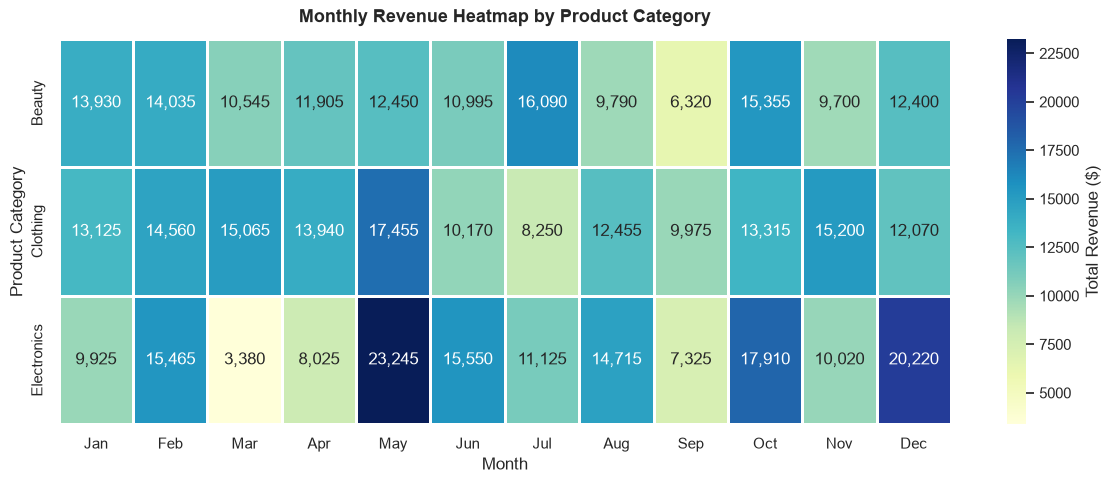

Month,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
Product Category,,,,,,,,,,,,
Beauty,"$13,930","$14,035","$10,545","$11,905","$12,450","$10,995","$16,090","$9,790","$6,320","$15,355","$9,700","$12,400"
Clothing,"$13,125","$14,560","$15,065","$13,940","$17,455","$10,170","$8,250","$12,455","$9,975","$13,315","$15,200","$12,070"
Electronics,"$9,925","$15,465","$3,380","$8,025","$23,245","$15,550","$11,125","$14,715","$7,325","$17,910","$10,020","$20,220"


In [34]:
# Create ordered Month categorical column
month_order = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
df["Month"] = pd.Categorical(df["Date"].dt.strftime("%b"), categories=month_order, ordered=True)

# Pivot table: Total Revenue by Category across Months
monthly_category_pivot = df.pivot_table(
    index="Product Category", 
    columns="Month", 
    values="Total Amount", 
    aggfunc="sum"
)

# Plot Heatmap
plt.figure(figsize=(12, 5))
sns.heatmap(
    monthly_category_pivot, 
    annot=True, 
    fmt=",.0f", 
    cmap="YlGnBu", 
    linewidths=0.8, 
    cbar_kws={"label": "Total Revenue ($)"}
)

plt.title("Monthly Revenue Heatmap by Product Category", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Month")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

# Display Pivot Matrix in Jupyter Notebook
display(monthly_category_pivot.style.format("${:,.0f}"))